# 422 – A qGAN for Two-Dimensional, Correlated Data

In `421` the data had one dimension.  Now each sample is a **pair** $(x_0, x_1)$, and the two
coordinates are **correlated**: when $x_0$ is large, $x_1$ tends to be large too.

We give each dimension its own qubits – 2 qubits for $x_0$ and 2 for $x_1$, i.e. a 4 × 4 grid
and 16 basis states.  The generator must learn the *joint* distribution.

**Why entanglement matters.** If the generator's state were a product
$|\psi_0\rangle\otimes|\psi_1\rangle$ of the $x_0$-qubits and the $x_1$-qubits, the two
coordinates would be *independent* – no correlation possible.  The CNOTs of the ansatz
entangle the two registers, and that entanglement is what lets the circuit represent
correlation.

**You will learn to** set up a multi-dimensional qGAN, inspect a joint distribution as a heat
map and measure the learned correlation.

The training loop is the one from `421`, imported from `qml_qgan.py`.

**Prerequisites:** `421`.

In [1]:
# === BACKEND SETUP (qiskit_backend_config) ===
# -----------------------------------------------
# Common backend helper — works with Qiskit 2.x / qiskit-aer / qiskit-ibm-runtime.
# Provides drop-in replacements for the removed Aer, BasicAer, execute(), and IBMQ.
#
# HOW TO SELECT A BACKEND
# -----------------------
# Simulator (default, runs locally — no credentials needed):
#   BACKEND_NAME = "qasm_simulator"        # shot-based measurements
#   BACKEND_NAME = "statevector_simulator" # full statevector
#   BACKEND_NAME = "unitary_simulator"     # full unitary matrix
#
# Real IBM hardware (requires IBM Quantum account):
#   Set the environment variable:  IBM_QUANTUM_TOKEN=<your_token>
#   Then choose a device, e.g.:
#   BACKEND_NAME = "ibm_brisbane"
#   BACKEND_NAME = "least_busy"  # auto-pick least-busy device
#
import sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath('__file__')))
from qiskit_backend_config import (get_backend, execute, Aer, BasicAer,
                                   IBMQ, least_busy, job_monitor, assemble, combine)

# ── Choose your backend here ──────────────────────────────────────────────
BACKEND_NAME = "qasm_simulator"  # change to a device name for real hardware
# ── (Optional) IBM Quantum token — leave empty to use env var or saved creds
IBM_QUANTUM_TOKEN = os.environ.get("IBM_QUANTUM_TOKEN", "")

# Build the backend object used throughout this notebook
_token_arg = IBM_QUANTUM_TOKEN if IBM_QUANTUM_TOKEN else None
backend = get_backend(BACKEND_NAME, token=_token_arg)
print(f'Backend ready: {backend}')


Backend ready: LegacyAerSimulator('aer_simulator')


In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch

# the qGAN building blocks written out step by step in 421, packaged for re-use
from qml_qgan import (discretize, generator_circuit, make_generator, Discriminator,
                      train_qgan, generated_distribution, plot_history)

torch.manual_seed(42)
def show_2d(prob_data, prob_gen, grid_elements, num_qubits, labels):
    """Side-by-side heat maps of two distributions over a 2-D grid."""
    n0, n1 = 2 ** num_qubits[0], 2 ** num_qubits[1]
    x0 = np.unique(grid_elements[:, 0]); x1 = np.unique(grid_elements[:, 1])
    fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
    vmax = max(prob_data.max(), prob_gen.max())
    for ax, p, title in zip(axs, (prob_data, prob_gen), ('training data', 'trained generator')):
        im = ax.imshow(p.reshape(n1, n0), origin='lower', cmap='Blues', vmin=0, vmax=vmax)
        ax.set_xticks(range(n0), [f'{v:.3g}' for v in x0]); ax.set_yticks(range(n1), [f'{v:.3g}' for v in x1])
        ax.set(title=title, xlabel=labels[0], ylabel=labels[1])
        for i in range(n1):
            for j in range(n0):
                ax.text(j, i, f'{p.reshape(n1, n0)[i, j]:.2f}', ha='center', va='center', fontsize=9)
    fig.colorbar(im, ax=axs, shrink=0.8)
    plt.show()


def correlation(prob, grid_elements):
    """Pearson correlation of the two coordinates under the distribution prob."""
    x, y = grid_elements[:, 0], grid_elements[:, 1]
    mx, my = prob @ x, prob @ y
    cov = prob @ ((x - mx) * (y - my))
    return cov / np.sqrt((prob @ (x - mx) ** 2) * (prob @ (y - my) ** 2))

## Training data

2000 samples of a 2-D normal distribution with mean $(0, 0)$, unit variances and correlation
0.8.  `discretize` snaps them onto a 4 × 4 grid over $[-2, 2]^2$ (samples outside are dropped).
Basis state $|i\rangle$ uses its **lower two bits for $x_0$** and its **upper two bits for $x_1$**.

grid values per dimension: [-2.   -0.67  0.67  2.  ]
correlation of the gridded data: 0.631


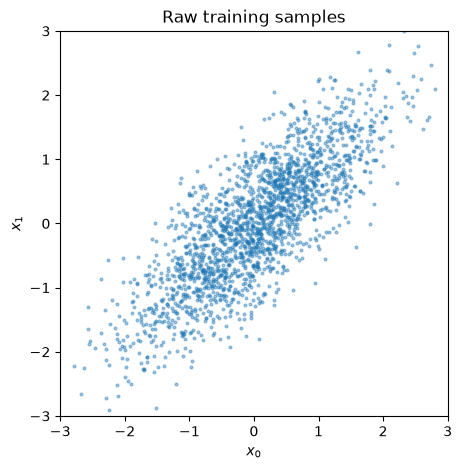

In [3]:
rng = np.random.default_rng(71)
real_data = rng.multivariate_normal(mean=[0, 0], cov=[[1, 0.8], [0.8, 1]], size=2000)
bounds = [[-2, 2], [-2, 2]]
num_qubits = [2, 2]

grid_elements, prob_data = discretize(real_data, bounds, num_qubits)
print("grid values per dimension:", np.unique(grid_elements[:, 0]).round(2))
print(f"correlation of the gridded data: {correlation(prob_data, grid_elements):.3f}")

plt.figure(figsize=(5, 5))
plt.scatter(real_data[:, 0], real_data[:, 1], s=4, alpha=0.4)
plt.xlim(-3, 3); plt.ylim(-3, 3)
plt.title('Raw training samples'); plt.xlabel('$x_0$'); plt.ylabel('$x_1$')
plt.show()

## Generator and discriminator

Same recipe as in `421`, now with 4 qubits (16 weights) and a discriminator with 2 inputs.

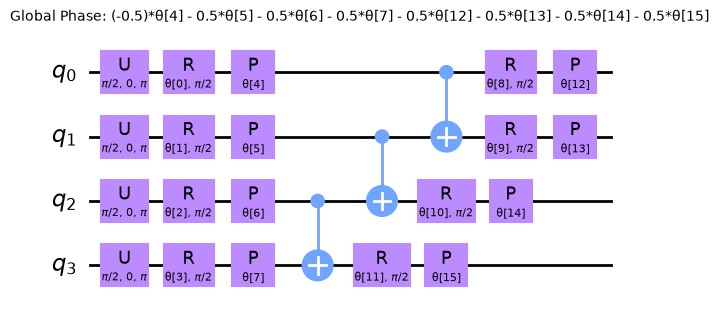

In [4]:
qc = generator_circuit(num_qubits, reps=1)
generator = make_generator(qc, seed=42)
discriminator = Discriminator(input_size=2)
qc.decompose().draw(output='mpl', style='clifford', fold=-1)

## Training (about 4 minutes)

training time: 2.1 min,  final relative entropy: 0.0442


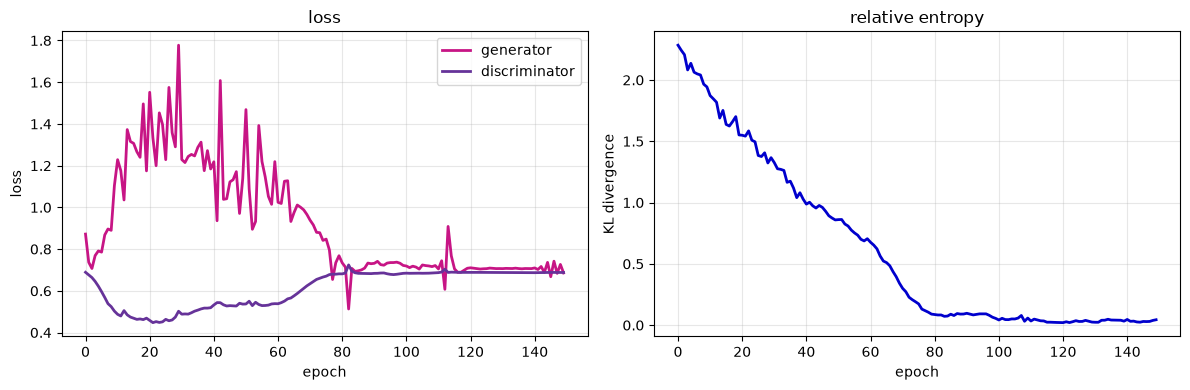

In [5]:
start = time.time()
history = train_qgan(generator, discriminator, grid_elements, prob_data, num_epochs=150)
print(f"training time: {(time.time() - start) / 60:.1f} min,  final relative entropy: {history['rel_entr'][-1]:.4f}")
plot_history(history)

## Did it learn the joint distribution?

Each heat-map cell is the probability of one grid point.  The mass of the data lies along the
diagonal – that is the correlation.

Note that the gridded data has a correlation of about 0.63 rather than 0.8: snapping to only
4 values per axis loses detail.  The fair comparison is generator vs *gridded* data.

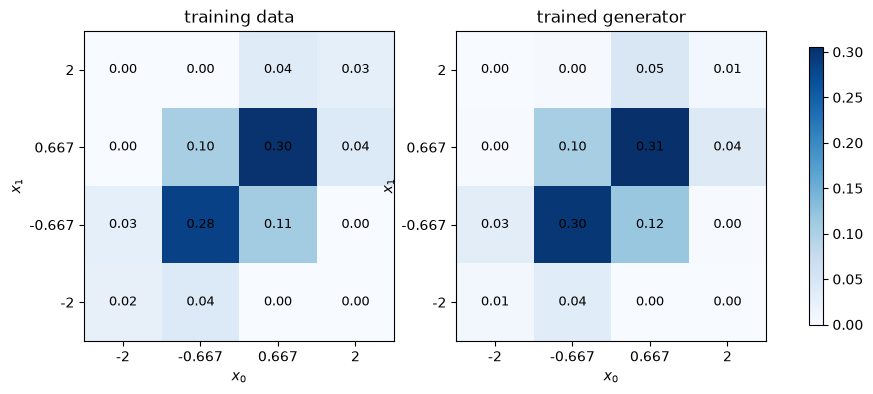

correlation – training data: 0.631   generator: 0.539


In [6]:
prob_gen = generated_distribution(generator)
show_2d(prob_data, prob_gen, grid_elements, num_qubits, ('$x_0$', '$x_1$'))
print(f"correlation – training data: {correlation(prob_data, grid_elements):.3f}   "
      f"generator: {correlation(prob_gen, grid_elements):.3f}")

## Key takeaways
* Multi-dimensional data: one qubit register per dimension; the grid has $2^{n_0+n_1}$ points.
* Correlations between dimensions need **entanglement** between the registers.
* The grid is coarse (4 values per axis).  More qubits give finer resolution – but more
  weights and longer training.

## Try it yourself
1. Change the correlation to 0 (`cov=[[1, 0], [0, 1]]`) and to −0.8.  Does the generator follow?
2. Remove the entanglement: build the circuit yourself with Hadamards and
   `efficient_su2(4, reps=1, entanglement=[])`.  Can it still learn correlation 0.8?
3. Use `num_qubits = [3, 3]` (64 grid points).  How does the training time change?

**Next:** `423-QGAN-04-Car-Sale-Data` – the same approach on a real dataset.